In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import json
import numpy as np

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

mpl.rc('text', usetex=True)
mpl.rcParams['text.latex.preamble'] = r"\usepackage{amsmath}"

tex_fonts = {"font.family": "serif",
             "font.size": 11,
             "axes.labelsize": 11,
             "legend.fontsize": 8,
             "xtick.labelsize": 8,
             "ytick.labelsize": 8}

plt.rcParams.update(tex_fonts)

marker_options = {'marker': 'o',
                  'markeredgecolor': 'black',
                  'markeredgewidth': 1.0,
                  'markersize': 5}

cmap = sns.color_palette('deep', as_cmap=True)

def set_size(width="revtex4.2", fraction=1, subplots=(1, 1), golden_ratio = 0.6180339887498949):
    """Set figure dimensions to avoid scaling in LaTeX.

    Parameters
    ----------
    width: float or string
            Document width in points, or string of predined document type
    fraction: float, optional
            Fraction of the width which you wish the figure to occupy
    subplots: array-like, optional
            The number of rows and columns of subplots.
    Returns
    -------
    fig_dim: tuple
            Dimensions of figure in inches
    """
    if width == 'revtex4.2':
        width_pt = 510.0
    else:
        width_pt = width

    # Width of figure (in pts)
    fig_width_pt = width_pt * fraction
    # Convert from pt to inches
    inches_per_pt = 1 / 72.27

    # Figure width in inches
    fig_width_in = fig_width_pt * inches_per_pt
    # Figure height in inches
    fig_height_in = fig_width_in * golden_ratio * (subplots[0] / subplots[1])

    return (fig_width_in, fig_height_in)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
def load_training_results(file_name: str, data_folder = "../data/optimisation_data/"):
    """
    Save results of the function 'optimize_tn' in json format. 
    Complex values are transformed into strings for json serialisation.
    """
    with open(data_folder + file_name, 'r') as file:
        res = json.load(file)

        # Params during training
        res['params'] = [{int(k): np.array(v, dtype=complex) for k, v in p.items()} for p in res['params']]

        # Params of the MPOs, self-explanatory
        mpo_params_keys = [] #['params_true_mpo', 'params_inv_opt_mpo', 'params_inv_true_mpo']
        for key in mpo_params_keys:
            res[key] = {int(k): np.real_if_close(np.array(v, dtype=complex)) for k, v in res[key].items()}
        
        ignore_keys = ['probs', 'data_file', 'params', 'noise_type', 'lr'] + mpo_params_keys
        for k in set(res.keys()).difference(ignore_keys):
            res[k] = np.real_if_close(np.array(res[k], dtype=complex))
        
    return res

In [4]:
data = load_training_results('vtt_4q.json')

print("File metadata:")
for md in ['seed', 'noise_type', 'data_file', 'batch_size', 'lr', 'virtual_bd', 'kraus_bd']:
    print(f" > {md:10s} = {data[md]}")

frob_dist  = data['frob_distance']
test_loss  = data['test_loss']
trace_lpdo = data['lpdo_trace']

File metadata:
 > seed       = 34343400.0
 > noise_type = None
 > data_file  = /Users/francesco.grieco/Projects/VTT-Noise-Learning/TN_noise/data/physics_brickwork_test_exp_2_IQM_VTT_50q/physics_brickwork_test_exp_2_IQM_VTT_50q_run0_circ3.json
 > batch_size = 250.0
 > lr         = exponential_decay
 > virtual_bd = 4.0
 > kraus_bd   = 4.0


In [7]:
frob_dist

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

/var/folders/g9/lcpd651j0l70vzr038j9yrw40000gn/T/ipykernel_82717/2875403456.py:6: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale('log')


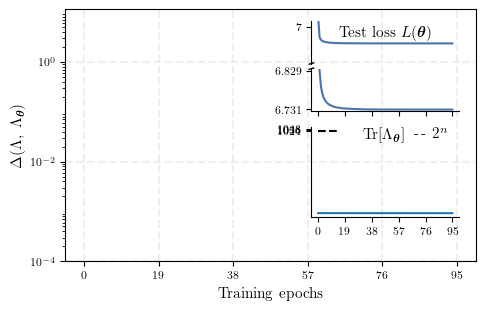

In [5]:
fig, ax = plt.subplots(figsize=set_size(fraction = 0.75))

# Frobenius distance
ax.plot(frob_dist, color = cmap[0], **marker_options)
ax.set_xticks(np.linspace(0, len(trace_lpdo)-1, 6, dtype=int))
ax.set_yscale('log')
ax.set_yticks([1e0, 1e-2, 1e-4])

# Subplot showing the test error
test_ax = ax.inset_axes([0.6, 0.595, 0.36, 0.36])
test_ax.plot(test_loss, color = cmap[0])

test_ax.set_ylim([6.4, 7.1])
test_ax.spines['bottom'].set_visible(False)
test_ax.tick_params(bottom=False, labelbottom=False)
test_ax.set_yticks([7])

y0, y1 = test_ax.get_ylim()
test_ax.text(len(trace_lpdo) / 2, 0.99 * y1, r"Test loss $L({\boldsymbol{\theta}})$", ha="center", va="top")

divider = make_axes_locatable(test_ax)
ax1bis = divider.append_axes("bottom", size="100%", pad=0.05)
ax1bis.plot(test_loss, color = cmap[0])
ax1bis.set_ylim([min(test_loss) - 0.005, np.max(test_loss[1:]) + 0.005])
ax1bis.spines['top'].set_visible(False)
ax1bis.set_yticks([round(min(test_loss) + 0.001, 3), round(np.max(test_loss[1:]) - 0.001, 3)])
ax1bis.set_xticks(np.linspace(0, len(trace_lpdo)-1, 6, dtype=int))
ax1bis.set_xticklabels([])

# From https://matplotlib.org/examples/pylab_examples/broken_axis.html
d = .015  # how big to make the diagonal lines in axes coordinates
# arguments to pass to plot, just so we don't keep repeating them
kwargs = dict(transform=test_ax.transAxes, lw=1, color='k', clip_on=False)
test_ax.plot((-d, +d), (-d, +d), **kwargs)        # top-left diagonal
kwargs.update(transform=ax1bis.transAxes)  # switch to the bottom axes
ax1bis.plot((-d, +d), (1 - d, 1 + d), **kwargs)  # bottom-left diagonal

test_ax.spines['top'].set_visible(False)
test_ax.spines['right'].set_visible(False)
ax1bis.spines['top'].set_visible(False)
ax1bis.spines['right'].set_visible(False)
ax1bis.set(facecolor = "None")
test_ax.set(facecolor = "None")

trace_ax = ax.inset_axes([0.6, 0.175, 0.36, 0.36])
trace_ax.hlines(1024, 0, 15, ls="--", color="k")
trace_ax.plot(trace_lpdo)
trace_ax.spines['top'].set_visible(False)
trace_ax.spines['right'].set_visible(False)
y0, y1 = trace_ax.get_ylim()
trace_ax.text(len(trace_lpdo) / 2 - 1, y1 - 2, r"$\textrm{Tr}[\Lambda_{\boldsymbol{\theta}}]$", ha="center", va="top")
trace_ax.text(1.9 * (len(trace_lpdo) / 2), y1 - 2, r"-\,- $2^n$", ha="right", va="top")
trace_ax.set_xticks(np.linspace(0, len(trace_lpdo)-1, 6, dtype=int))
trace_ax.set_yticks([1024, 1036, 1048])
trace_ax.set(facecolor = "None")

ax.set_ylabel(r"$\Delta(\Lambda,~\Lambda_{\boldsymbol{\theta}})$", fontsize=11)
ax.set_xlabel("Training epochs", fontsize=11)
ax.grid(ls = "--", lw = 1.5, alpha = 0.2)
plt.tight_layout

#y0, y1 = plt.get_ylim()
#axs[0].text(len(trace_lpdo) / 2, 0.5 * y1, r"$\mathcal{D}(\Lambda,~\Lambda_{\boldsymbol{\theta}})$", ha="center", va="top")
#axs[1].text(len(trace_lpdo) / 2, 0.99 * y1, r"Test loss $\mathcal{L}({\boldsymbol{\theta}})$", ha="center", va="top")
plt.savefig("example_lpdo_training.pdf", format="pdf", bbox_inches='tight')

/var/folders/g9/lcpd651j0l70vzr038j9yrw40000gn/T/ipykernel_82717/2171522496.py:6: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  axs[0].set_yscale('log')


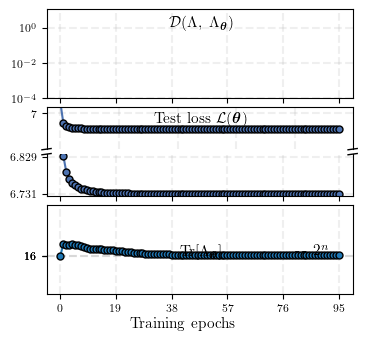

In [8]:
fig, axs = plt.subplots(3, 1, figsize = set_size(fraction = 0.5, subplots=(1.5, 1)), gridspec_kw={'height_ratios': [1., 1, 1]})

axs[0].plot(frob_dist, color = cmap[0], **marker_options)
axs[0].set_xticks(np.linspace(0, len(trace_lpdo)-1, 6, dtype=int))
axs[0].set_xticklabels([])
axs[0].set_yscale('log')
axs[0].set_yticks([1e0, 1e-2, 1e-4])

y0, y1 = axs[0].get_ylim()
axs[0].text(len(trace_lpdo) / 2, 0.5 * y1, r"$\mathcal{D}(\Lambda,~\Lambda_{\boldsymbol{\theta}})$", ha="center", va="top")

axs[1].plot(test_loss, color = cmap[0], **marker_options)
axs[1].set_ylim([6.4, 7.1])
axs[1].spines['bottom'].set_visible(False)
axs[1].tick_params(bottom=False, labelbottom=False)
axs[1].set_yticks([7])

y0, y1 = axs[1].get_ylim()
axs[1].text(len(trace_lpdo) / 2, 0.99 * y1, r"Test loss $\mathcal{L}({\boldsymbol{\theta}})$", ha="center", va="top")

divider = make_axes_locatable(axs[1])
ax1bis = divider.append_axes("bottom", size="100%", pad=0.05)
ax1bis.plot(test_loss, color = cmap[0], **marker_options)
ax1bis.set_ylim([min(test_loss) - 0.005, np.max(test_loss[1:]) + 0.005])
ax1bis.spines['top'].set_visible(False)
ax1bis.set_yticks([round(min(test_loss) + 0.001, 3), round(np.max(test_loss[1:]) - 0.001, 3)])
ax1bis.set_xticks(np.linspace(0, len(trace_lpdo)-1, 6, dtype=int))
ax1bis.set_xticklabels([])

# From https://matplotlib.org/examples/pylab_examples/broken_axis.html
d = .015  # how big to make the diagonal lines in axes coordinates
# arguments to pass to plot, just so we don't keep repeating them
kwargs = dict(transform=axs[1].transAxes, lw=1, color='k', clip_on=False)
axs[1].plot((-d, +d), (-d, +d), **kwargs)        # top-left diagonal
axs[1].plot((1 - d, 1 + d), (-d, +d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1bis.transAxes)  # switch to the bottom axes
ax1bis.plot((-d, +d), (1 - d, 1 + d), **kwargs)  # bottom-left diagonal
ax1bis.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)  # bottom-right diagonal

axs[2].hlines(1024, 0, 15, ls="--", color="k")
axs[2].plot(trace_lpdo, **marker_options)
axs[2].set_yticks(np.linspace(min(trace_lpdo), max(trace_lpdo), 3, dtype=int))
axs[2].set_ylim([min(trace_lpdo)-2, max(trace_lpdo)+2])
axs[2].set_xticks(np.linspace(0, len(trace_lpdo)-1, 6, dtype=int))

y0, y1 = axs[2].get_ylim()
axs[2].text(len(trace_lpdo) / 2, y1 - 2, r"$\textrm{Tr}[\Lambda_{\boldsymbol{\theta}}]$", ha="center", va="top")
axs[2].text(1.9 * (len(trace_lpdo) / 2), y1 - 2, r"-\,- $2^n$", ha="right", va="top")

fig.supxlabel("Training epochs", fontsize=11)
plt.tight_layout(pad=0.2)

axs[0].grid(ls = "--", lw = 1.5, alpha = 0.2)
axs[1].grid(ls = "--", lw = 1.5, alpha = 0.2)
ax1bis.grid(ls = "--", lw = 1.5, alpha = 0.2)
axs[2].grid(ls = "--", lw = 1.5, alpha = 0.2)

#plt.savefig("lpdo_training.pdf", format="pdf", bbox_inches='tight')